# 05 — Customer Segmentation Using K-Means

## Mục tiêu

Notebook này thực hiện phân khúc khách hàng thương mại điện tử
bằng thuật toán K-Means.

Các bước chính:

1. Khám phá và lựa chọn đặc trưng hành vi.
2. Kiểm tra và chuẩn hóa dữ liệu phân cụm.
3. Xác định số cụm K bằng Elbow Method và Silhouette Score.
4. Huấn luyện mô hình K-Means.
5. Phân tích đặc điểm và quy mô từng nhóm khách hàng.
6. Trực quan hóa các cụm bằng PCA.
7. Lưu mô hình để tích hợp vào ứng dụng.

K-Means là thuật toán học không giám sát, không sử dụng
Purchase_Level làm nhãn trong quá trình huấn luyện.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline


RANDOM_STATE = 42

pd.set_option("display.max_columns", None)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
DATA_PATH = Path(
    "../data/processed/ecommerce_customer_behavior_with_target.csv"
)

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (49960, 26)

Columns:
['Age', 'Gender', 'Country', 'City', 'Membership_Years', 'Login_Frequency', 'Session_Duration_Avg', 'Pages_Per_Session', 'Cart_Abandonment_Rate', 'Wishlist_Items', 'Total_Purchases', 'Average_Order_Value', 'Days_Since_Last_Purchase', 'Discount_Usage_Rate', 'Returns_Rate', 'Email_Open_Rate', 'Customer_Service_Calls', 'Product_Reviews_Written', 'Social_Media_Engagement_Score', 'Mobile_App_Usage', 'Payment_Method_Diversity', 'Lifetime_Value', 'Credit_Balance', 'Churned', 'Signup_Quarter', 'Purchase_Level']


,Age,Gender,Country,City,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,Total_Purchases,Average_Order_Value,Days_Since_Last_Purchase,Discount_Usage_Rate,Returns_Rate,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned,Signup_Quarter,Purchase_Level
0,43.0,Male,France,Marseille,2.9,14.0,27.4,6.0,50.6,3.0,9.0,94.72,34.0,46.40,2.0,17.9,9.0,4.0,16.3,20.8,1.0,953.33,2278.0,0,Q1,Low
1,36.0,Male,UK,Manchester,1.6,15.0,42.7,10.3,37.7,1.0,19.5,82.45,71.0,57.96,9.2,42.8,7.0,3.0,27.6,23.3,3.0,1067.47,3028.0,0,Q4,High
2,45.0,Female,Canada,Vancouver,2.9,10.0,24.8,1.6,70.9,1.0,9.1,165.52,11.0,12.24,11.5,0.0,4.0,1.0,27.6,8.8,2.0,1289.75,2317.0,0,Q4,Low
3,56.0,Female,USA,New York,2.6,10.0,38.4,14.8,41.7,9.0,15.0,147.33,47.0,44.10,5.4,41.4,2.0,5.0,85.9,31.0,3.0,2340.92,2674.0,0,Q1,Medium
4,35.0,Male,India,Delhi,3.1,29.0,51.4,8.4,19.1,9.0,32.5,141.30,73.0,25.20,5.5,37.9,1.0,11.0,83.0,50.4,4.0,3041.29,5354.0,0,Q4,High


In [3]:
CLUSTER_FEATURES = [
    "Login_Frequency",
    "Session_Duration_Avg",
    "Pages_Per_Session",
    "Cart_Abandonment_Rate",
    "Wishlist_Items",
    "Total_Purchases",
    "Average_Order_Value",
    "Days_Since_Last_Purchase",
    "Discount_Usage_Rate",
    "Mobile_App_Usage",
]

missing_features = [
    col for col in CLUSTER_FEATURES
    if col not in df.columns
]

assert not missing_features, (
    f"Missing features: {missing_features}"
)

X_cluster = df[CLUSTER_FEATURES].copy()

print("Clustering dataset:", X_cluster.shape)
print("Selected features:", len(CLUSTER_FEATURES))

display(X_cluster.head())

Clustering dataset: (49960, 10)
Selected features: 10


,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,Total_Purchases,Average_Order_Value,Days_Since_Last_Purchase,Discount_Usage_Rate,Mobile_App_Usage
0,14.0,27.4,6.0,50.6,3.0,9.0,94.72,34.0,46.40,20.8
1,15.0,42.7,10.3,37.7,1.0,19.5,82.45,71.0,57.96,23.3
2,10.0,24.8,1.6,70.9,1.0,9.1,165.52,11.0,12.24,8.8
3,10.0,38.4,14.8,41.7,9.0,15.0,147.33,47.0,44.10,31.0
4,29.0,51.4,8.4,19.1,9.0,32.5,141.30,73.0,25.20,50.4


In [4]:
print("Missing values:")
print(X_cluster.isna().sum())

print("\nDuplicate rows:")
print(X_cluster.duplicated().sum())

print("\nInfinite values:")
print(
    np.isinf(X_cluster.to_numpy()).sum()
)

print("\nDescriptive statistics:")
display(X_cluster.describe().T)

Missing values:
Login_Frequency             0
Session_Duration_Avg        0
Pages_Per_Session           0
Cart_Abandonment_Rate       0
Wishlist_Items              0
Total_Purchases             0
Average_Order_Value         0
Days_Since_Last_Purchase    0
Discount_Usage_Rate         0
Mobile_App_Usage            0

Duplicate rows:
0

Infinite values:
0

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
Login_Frequency,49960.0,11.624560,7.810565,0.00,6.000,11.00,17.00,46.000000
Session_Duration_Avg,49960.0,27.602572,10.496993,1.00,20.200,26.80,34.00,75.600000
Pages_Per_Session,49960.0,8.717708,3.663784,1.00,6.200,8.40,11.00,24.100000
Cart_Abandonment_Rate,49960.0,57.046703,16.207647,0.00,46.475,58.10,68.70,100.000000
Wishlist_Items,49960.0,4.274560,3.060899,0.00,2.000,4.00,6.00,28.000000
Total_Purchases,49960.0,13.127062,6.998207,0.00,8.000,12.00,17.00,128.700000
Average_Order_Value,49960.0,123.107904,175.632790,26.38,87.050,112.96,144.44,9666.379178
Days_Since_Last_Purchase,49960.0,29.266813,28.866144,0.00,9.000,21.00,39.00,287.000000
Discount_Usage_Rate,49960.0,41.599280,20.201934,0.24,26.500,40.10,55.20,99.960000
Mobile_App_Usage,49960.0,19.293937,8.938777,0.00,13.200,18.60,24.60,61.900000


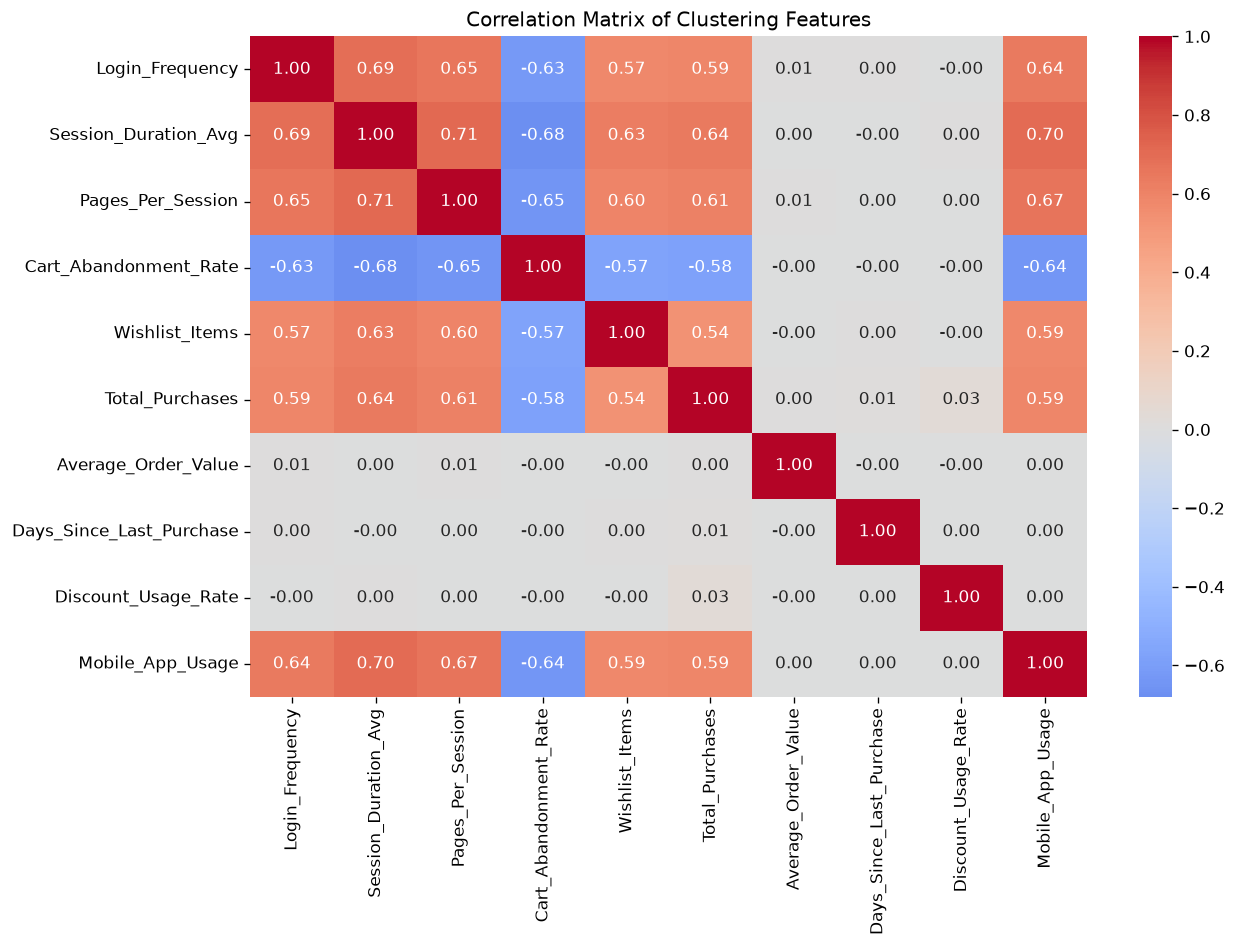

In [5]:
correlation_matrix = X_cluster.corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
)

plt.title(
    "Correlation Matrix of Clustering Features"
)

plt.tight_layout()
plt.show()

In [6]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(
    X_cluster
)

print("Scaled shape:", X_scaled.shape)
print(
    "NaN values:",
    np.isnan(X_scaled).sum(),
)
print(
    "Infinite values:",
    np.isinf(X_scaled).sum(),
)

scaled_df = pd.DataFrame(
    X_scaled,
    columns=CLUSTER_FEATURES,
)

display(scaled_df.head())

scaling_check = pd.DataFrame({
    "Mean": scaled_df.mean(),
    "Std": scaled_df.std(ddof=0),
})

display(scaling_check.round(4))

Scaled shape: (49960, 10)
NaN values: 0
Infinite values: 0


,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,Total_Purchases,Average_Order_Value,Days_Since_Last_Purchase,Discount_Usage_Rate,Mobile_App_Usage
0,0.304135,-0.019298,-0.741784,-0.397761,-0.416405,-0.589737,-0.161634,0.163972,0.237639,0.168488
1,0.432168,1.438277,0.431878,-1.193689,-1.069814,0.910662,-0.231496,1.445763,0.809867,0.448171
2,-0.207997,-0.266991,-1.942740,0.854747,-1.069814,-0.575448,0.241484,-0.632817,-1.453305,-1.173991
3,-0.207997,1.028631,1.660129,-0.946890,1.543824,0.267634,0.137915,0.614331,0.123787,1.309595
4,2.224630,2.267094,-0.086717,-2.341307,1.543824,2.768299,0.103581,1.515049,-0.811776,3.479936


,Mean,Std
Login_Frequency,0.0,1.0
Session_Duration_Avg,-0.0,1.0
Pages_Per_Session,0.0,1.0
Cart_Abandonment_Rate,0.0,1.0
Wishlist_Items,0.0,1.0
Total_Purchases,-0.0,1.0
Average_Order_Value,-0.0,1.0
Days_Since_Last_Purchase,0.0,1.0
Discount_Usage_Rate,0.0,1.0
Mobile_App_Usage,-0.0,1.0


In [7]:
OUTLIER_FEATURES = [
    "Total_Purchases",
    "Average_Order_Value",
]

outlier_stats = []

for col in OUTLIER_FEATURES:
    series = X_cluster[col]

    q01 = series.quantile(0.01)
    q99 = series.quantile(0.99)

    below = (series < q01).sum()
    above = (series > q99).sum()

    outlier_stats.append({
        "Feature": col,
        "Min": series.min(),
        "P01": q01,
        "Median": series.median(),
        "P99": q99,
        "Max": series.max(),
        "Below P01": below,
        "Above P99": above,
    })

outlier_stats_df = pd.DataFrame(outlier_stats)

display(outlier_stats_df.round(4))

Feature,Min,P01,Median,P99,Max,Below P01,Above P99
Total_Purchases,0.00,2.0000,12.00,31.2000,128.7000,185,452
Average_Order_Value,26.38,45.2818,112.96,252.0241,9666.3792,500,500


In [8]:
X_cluster_clipped = X_cluster.copy()

CLIP_BOUNDS = {}

for col in OUTLIER_FEATURES:
    lower = X_cluster[col].quantile(0.01)
    upper = X_cluster[col].quantile(0.99)

    CLIP_BOUNDS[col] = {
        "lower": float(lower),
        "upper": float(upper),
    }

    X_cluster_clipped[col] = (
        X_cluster_clipped[col]
        .clip(lower=lower, upper=upper)
    )

print("Original shape:", X_cluster.shape)
print("Clipped shape :", X_cluster_clipped.shape)

print("\nClipping bounds:")
for col, bounds in CLIP_BOUNDS.items():
    print(col, bounds)

Original shape: (49960, 10)
Clipped shape : (49960, 10)

Clipping bounds:
Total_Purchases {'lower': 2.0, 'upper': 31.200000000000003}
Average_Order_Value {'lower': 45.281800000000004, 'upper': 252.02409999999998}


In [9]:
comparison = []

for col in OUTLIER_FEATURES:
    comparison.append({
        "Feature": col,
        "Original Max": X_cluster[col].max(),
        "Clipped Max": X_cluster_clipped[col].max(),
        "Original Mean": X_cluster[col].mean(),
        "Clipped Mean": X_cluster_clipped[col].mean(),
        "Original Std": X_cluster[col].std(),
        "Clipped Std": X_cluster_clipped[col].std(),
    })

display(
    pd.DataFrame(comparison).round(4)
)

Feature,Original Max,Clipped Max,Original Mean,Clipped Mean,Original Std,Clipped Std
Total_Purchases,128.7000,31.2000,13.1271,13.0034,6.9982,6.2025
Average_Order_Value,9666.3792,252.0241,123.1079,119.2185,175.6328,43.3584


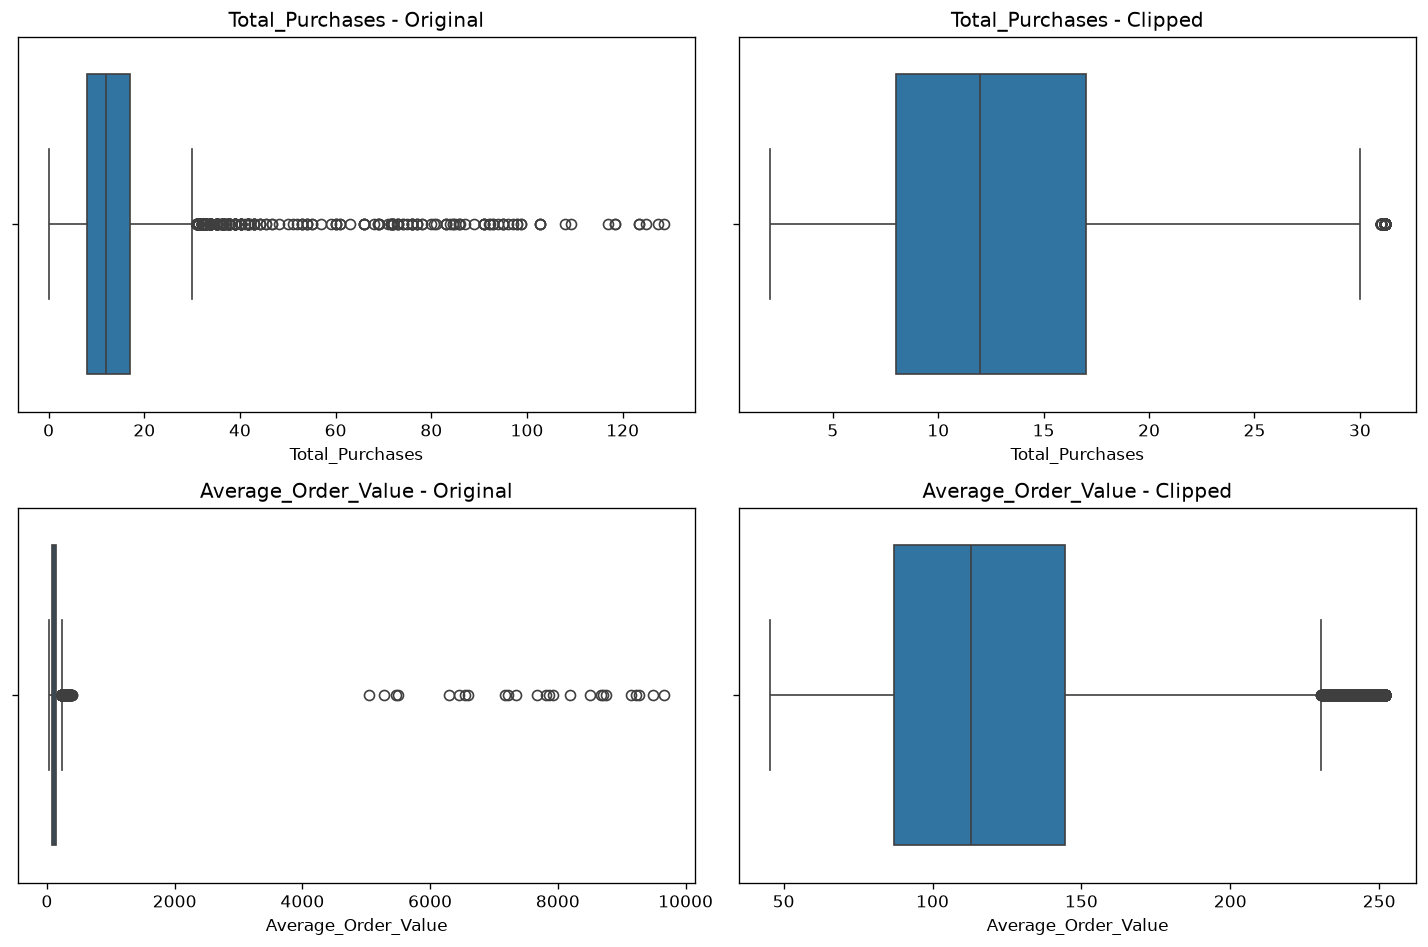

In [10]:
fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 8),
)

for i, col in enumerate(OUTLIER_FEATURES):
    sns.boxplot(
        x=X_cluster[col],
        ax=axes[i, 0],
    )
    axes[i, 0].set_title(f"{col} - Original")

    sns.boxplot(
        x=X_cluster_clipped[col],
        ax=axes[i, 1],
    )
    axes[i, 1].set_title(f"{col} - Clipped")

plt.tight_layout()
plt.show()

In [11]:
cluster_scaler = StandardScaler()

X_scaled_clipped = cluster_scaler.fit_transform(
    X_cluster_clipped
)

print("Scaled shape:", X_scaled_clipped.shape)
print("NaN:", np.isnan(X_scaled_clipped).sum())
print("Inf:", np.isinf(X_scaled_clipped).sum())

scaled_check = pd.DataFrame({
    "Feature": CLUSTER_FEATURES,
    "Mean": X_scaled_clipped.mean(axis=0),
    "Std": X_scaled_clipped.std(axis=0),
})

display(scaled_check.round(4))

Scaled shape: (49960, 10)
NaN: 0
Inf: 0


Feature,Mean,Std
Login_Frequency,0.0,1.0
Session_Duration_Avg,-0.0,1.0
Pages_Per_Session,0.0,1.0
Cart_Abandonment_Rate,0.0,1.0
Wishlist_Items,0.0,1.0
Total_Purchases,-0.0,1.0
Average_Order_Value,-0.0,1.0
Days_Since_Last_Purchase,0.0,1.0
Discount_Usage_Rate,0.0,1.0
Mobile_App_Usage,-0.0,1.0


In [12]:
changed_rows = (
    X_cluster[OUTLIER_FEATURES]
    != X_cluster_clipped[OUTLIER_FEATURES]
).any(axis=1)

print("Total customers:", len(X_cluster))
print("Changed customers:", changed_rows.sum())
print(
    "Changed percentage:",
    f"{changed_rows.mean() * 100:.2f}%",
)
print(
    "Original dataset unchanged:",
    df.shape == (49960, 26),
)

Total customers: 49960
Changed customers: 1626
Changed percentage: 3.25%
Original dataset unchanged: True


In [13]:
LOG_FEATURES = [
    "Total_Purchases",
    "Average_Order_Value",
]

X_cluster_log = X_cluster.copy()

for col in LOG_FEATURES:
    assert (X_cluster_log[col] >= 0).all(), (
        f"{col} contains negative values"
    )

    X_cluster_log[col] = np.log1p(
        X_cluster_log[col]
    )

print("Original shape:", X_cluster.shape)
print("Log shape     :", X_cluster_log.shape)

display(
    X_cluster_log[LOG_FEATURES].describe().T
)

Original shape: (49960, 10)
Log shape     : (49960, 10)


,count,mean,std,min,25%,50%,75%,max
Total_Purchases,49960.0,2.534555,0.491513,0.000000,2.197225,2.564949,2.890372,4.865224
Average_Order_Value,49960.0,4.726320,0.379443,3.309813,4.477905,4.735848,4.979764,9.176513


In [14]:
skew_comparison = pd.DataFrame({
    "Original": X_cluster[LOG_FEATURES].skew(),
    "Clipping": X_cluster_clipped[LOG_FEATURES].skew(),
    "Log1p": X_cluster_log[LOG_FEATURES].skew(),
})

display(skew_comparison.round(4))

,Original,Clipping,Log1p
Total_Purchases,2.7259,0.6385,-0.4683
Average_Order_Value,42.3522,0.7386,0.5307


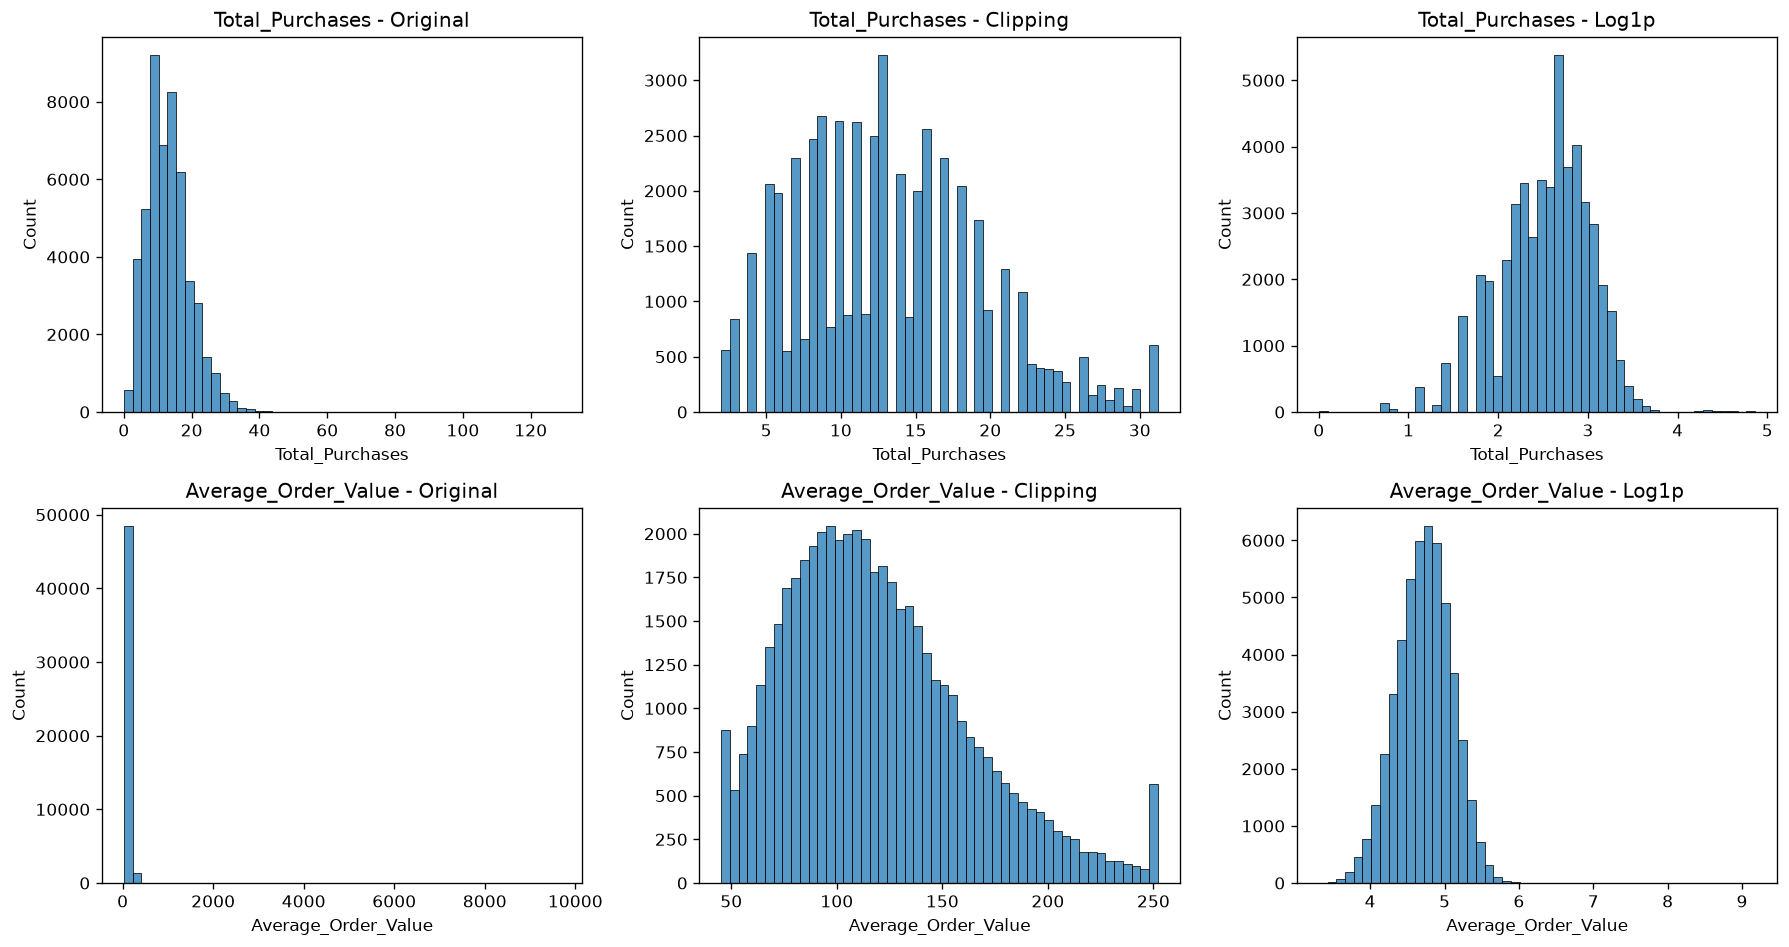

In [15]:
fig, axes = plt.subplots(
    2,
    3,
    figsize=(15, 8),
)

versions = [
    ("Original", X_cluster),
    ("Clipping", X_cluster_clipped),
    ("Log1p", X_cluster_log),
]

for row, feature in enumerate(LOG_FEATURES):
    for col, (name, data) in enumerate(versions):
        sns.histplot(
            data[feature],
            bins=50,
            ax=axes[row, col],
        )

        axes[row, col].set_title(
            f"{feature} - {name}"
        )

plt.tight_layout()
plt.show()

In [16]:
log_scaler = StandardScaler()

X_scaled_log = log_scaler.fit_transform(
    X_cluster_log
)

print("Log scaled shape:", X_scaled_log.shape)
print("NaN:", np.isnan(X_scaled_log).sum())
print("Inf:", np.isinf(X_scaled_log).sum())

assert np.isfinite(X_scaled_log).all()

log_scaling_check = pd.DataFrame({
    "Feature": CLUSTER_FEATURES,
    "Mean": X_scaled_log.mean(axis=0),
    "Std": X_scaled_log.std(axis=0),
})

display(log_scaling_check.round(4))

Log scaled shape: (49960, 10)
NaN: 0
Inf: 0


Feature,Mean,Std
Login_Frequency,0.0,1.0
Session_Duration_Avg,-0.0,1.0
Pages_Per_Session,0.0,1.0
Cart_Abandonment_Rate,0.0,1.0
Wishlist_Items,0.0,1.0
Total_Purchases,0.0,1.0
Average_Order_Value,0.0,1.0
Days_Since_Last_Purchase,0.0,1.0
Discount_Usage_Rate,0.0,1.0
Mobile_App_Usage,-0.0,1.0


In [17]:
distance_clipped = np.linalg.norm(
    X_scaled_clipped,
    axis=1,
)

distance_log = np.linalg.norm(
    X_scaled_log,
    axis=1,
)

distance_comparison = pd.DataFrame({
    "Clipping": pd.Series(distance_clipped).describe(
        percentiles=[0.5, 0.9, 0.95, 0.99]
    ),
    "Log1p": pd.Series(distance_log).describe(
        percentiles=[0.5, 0.9, 0.95, 0.99]
    ),
})

display(distance_comparison.round(4))

,Clipping,Log1p
count,49960.0000,49960.0000
mean,2.9732,2.9694
std,1.0771,1.0875
min,0.6115,0.5988
50%,2.7863,2.7757
90%,4.3282,4.3647
95%,5.0061,5.0020
99%,6.5475,6.4504
max,9.8977,12.4876


In [18]:
from sklearn.metrics import silhouette_score


K_VALUES = range(2, 7)
SILHOUETTE_SAMPLE_SIZE = 3000

CLUSTER_DATASETS = {
    "Clipping": X_scaled_clipped,
    "Log1p": X_scaled_log,
}

print("K values:", list(K_VALUES))
print("Silhouette sample size:", SILHOUETTE_SAMPLE_SIZE)

for name, data in CLUSTER_DATASETS.items():
    print(f"{name}: {data.shape}")

K values: [2, 3, 4, 5, 6]
Silhouette sample size: 3000
Clipping: (49960, 10)
Log1p: (49960, 10)


In [19]:
import time


experiment_results = []
cluster_size_results = []

for method_name, X_data in CLUSTER_DATASETS.items():
    print("=" * 65)
    print(f"PREPROCESSING METHOD: {method_name}")
    print("=" * 65)

    for k in K_VALUES:
        start_time = time.time()

        kmeans = KMeans(
            n_clusters=k,
            init="k-means++",
            n_init=10,
            random_state=RANDOM_STATE,
        )

        labels = kmeans.fit_predict(X_data)

        silhouette = silhouette_score(
            X_data,
            labels,
            sample_size=SILHOUETTE_SAMPLE_SIZE,
            random_state=RANDOM_STATE,
        )

        elapsed = time.time() - start_time

        cluster_sizes = np.bincount(
            labels,
            minlength=k,
        )

        experiment_results.append({
            "Method": method_name,
            "K": k,
            "Silhouette": silhouette,
            "Inertia": kmeans.inertia_,
            "Min Cluster Size": cluster_sizes.min(),
            "Max Cluster Size": cluster_sizes.max(),
            "Min Cluster (%)": cluster_sizes.min() / len(labels) * 100,
            "Time (s)": elapsed,
        })

        for cluster_id, size in enumerate(cluster_sizes):
            cluster_size_results.append({
                "Method": method_name,
                "K": k,
                "Cluster": cluster_id,
                "Size": int(size),
                "Percentage": size / len(labels) * 100,
            })

        print(
            f"K={k} | "
            f"Silhouette={silhouette:.4f} | "
            f"Inertia={kmeans.inertia_:.2f} | "
            f"Min cluster={cluster_sizes.min():,} | "
            f"Time={elapsed:.2f}s"
        )

experiment_df = pd.DataFrame(experiment_results)
cluster_sizes_df = pd.DataFrame(cluster_size_results)

print("\nExperiment completed.")

PREPROCESSING METHOD: Clipping
K=2 | Silhouette=0.2799 | Inertia=335272.54 | Min cluster=18,660 | Time=0.65s
K=3 | Silhouette=0.1689 | Inertia=295590.59 | Min cluster=9,603 | Time=0.28s
K=4 | Silhouette=0.1707 | Inertia=275652.44 | Min cluster=4,474 | Time=0.40s
K=5 | Silhouette=0.1488 | Inertia=259927.98 | Min cluster=3,860 | Time=0.46s
K=6 | Silhouette=0.1252 | Inertia=246097.39 | Min cluster=3,569 | Time=0.54s
PREPROCESSING METHOD: Log1p
K=2 | Silhouette=0.2693 | Inertia=338100.77 | Min cluster=19,713 | Time=0.26s
K=3 | Silhouette=0.1675 | Inertia=297568.53 | Min cluster=10,226 | Time=0.33s
K=4 | Silhouette=0.1686 | Inertia=277750.68 | Min cluster=4,438 | Time=0.59s
K=5 | Silhouette=0.1232 | Inertia=261940.07 | Min cluster=4,026 | Time=0.65s
K=6 | Silhouette=0.1193 | Inertia=248024.51 | Min cluster=3,430 | Time=0.72s

Experiment completed.


In [20]:
display(
    experiment_df
    .sort_values(["K", "Method"])
    .round(4)
)

silhouette_comparison = experiment_df.pivot(
    index="K",
    columns="Method",
    values="Silhouette",
)

display(silhouette_comparison.round(4))

,Method,K,Silhouette,Inertia,Min Cluster Size,Max Cluster Size,Min Cluster (%),Time (s)
0,Clipping,2,0.2799,335272.5369,18660,31300,37.3499,0.6524
5,Log1p,2,0.2693,338100.7705,19713,30247,39.4576,0.2608
1,Clipping,3,0.1689,295590.5932,9603,20640,19.2214,0.2795
6,Log1p,3,0.1675,297568.5252,10226,20524,20.4684,0.3333
2,Clipping,4,0.1707,275652.4382,4474,19029,8.9552,0.3970
7,Log1p,4,0.1686,277750.6811,4438,18176,8.8831,0.5888
3,Clipping,5,0.1488,259927.9831,3860,15496,7.7262,0.4608
8,Log1p,5,0.1232,261940.0668,4026,15670,8.0584,0.6463
4,Clipping,6,0.1252,246097.3913,3569,11728,7.1437,0.5410
9,Log1p,6,0.1193,248024.5091,3430,11460,6.8655,0.7180


Method,Clipping,Log1p
K,,
2,0.2799,0.2693
3,0.1689,0.1675
4,0.1707,0.1686
5,0.1488,0.1232
6,0.1252,0.1193


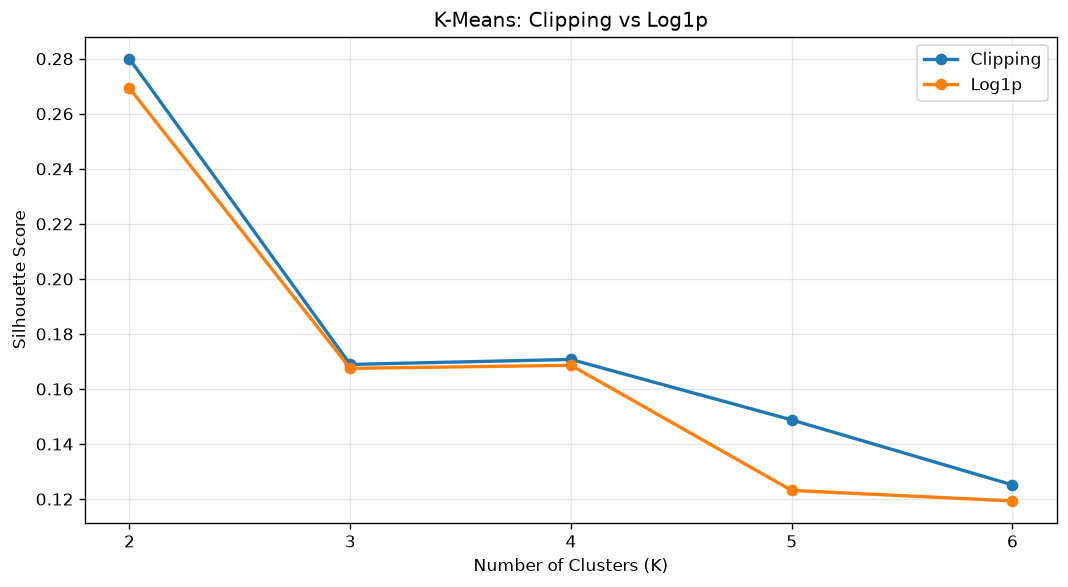

In [21]:
plt.figure(figsize=(9, 5))

for method_name in CLUSTER_DATASETS:
    subset = experiment_df[
        experiment_df["Method"] == method_name
    ]

    plt.plot(
        subset["K"],
        subset["Silhouette"],
        marker="o",
        linewidth=2,
        label=method_name,
    )

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("K-Means: Clipping vs Log1p")
plt.xticks(list(K_VALUES))
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

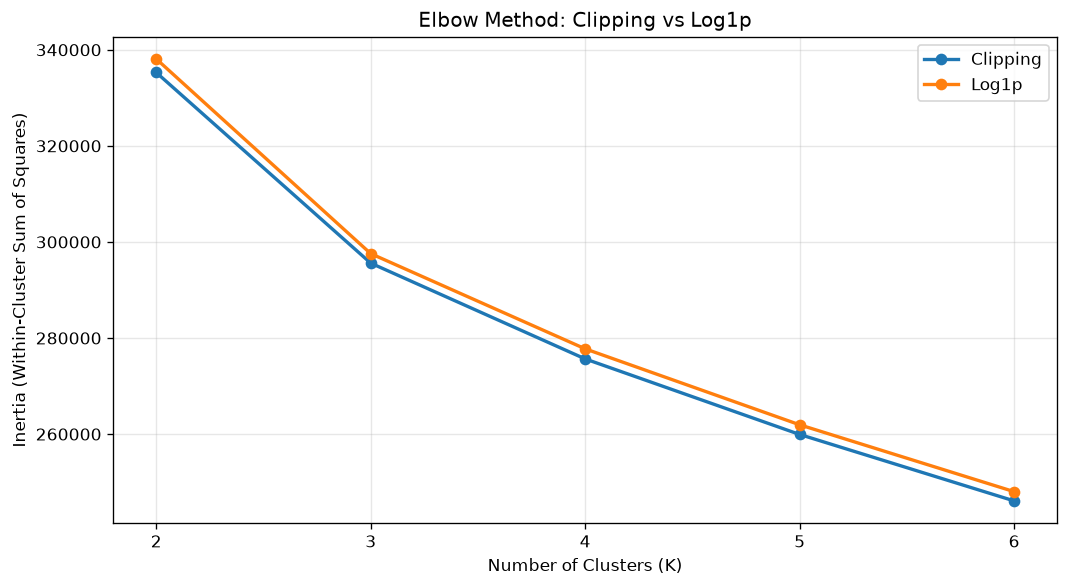

In [22]:
plt.figure(figsize=(9, 5))

for method_name in CLUSTER_DATASETS:
    subset = experiment_df[
        experiment_df["Method"] == method_name
    ]

    plt.plot(
        subset["K"],
        subset["Inertia"],
        marker="o",
        linewidth=2,
        label=method_name,
    )

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia (Within-Cluster Sum of Squares)")
plt.title("Elbow Method: Clipping vs Log1p")
plt.xticks(list(K_VALUES))
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [23]:
cluster_size_pivot = cluster_sizes_df.pivot_table(
    index=["Method", "K"],
    columns="Cluster",
    values="Percentage",
)

display(cluster_size_pivot.round(2))

Cluster         0      1      2      3      4      5
Method   K                                          
Clipping 2  62.65  37.35    NaN    NaN    NaN    NaN
         3  19.22  41.31  39.47    NaN    NaN    NaN
         4  34.90  38.09  18.06   8.96    NaN    NaN
         5  29.15  15.61  31.02  16.50   7.73    NaN
         6  13.18  10.72   7.14  22.03  23.47  23.45
Log1p    2  60.54  39.46    NaN    NaN    NaN    NaN
         3  41.08  38.45  20.47    NaN    NaN    NaN
         4  19.59   8.88  36.38  35.15    NaN    NaN
         5   8.06  31.37  24.75  11.92  23.91    NaN
         6  22.94  20.78  15.50  11.01  22.90   6.87

In [24]:
ranked_experiments = (
    experiment_df
    .sort_values(
        by="Silhouette",
        ascending=False,
    )
    .reset_index(drop=True)
)

display(
    ranked_experiments[
        [
            "Method",
            "K",
            "Silhouette",
            "Inertia",
            "Min Cluster (%)",
            "Time (s)",
        ]
    ].round(4)
)

,Method,K,Silhouette,Inertia,Min Cluster (%),Time (s)
0,Clipping,2,0.2799,335272.5369,37.3499,0.6524
1,Log1p,2,0.2693,338100.7705,39.4576,0.2608
2,Clipping,4,0.1707,275652.4382,8.9552,0.3970
3,Clipping,3,0.1689,295590.5932,19.2214,0.2795
4,Log1p,4,0.1686,277750.6811,8.8831,0.5888
5,Log1p,3,0.1675,297568.5252,20.4684,0.3333
6,Clipping,5,0.1488,259927.9831,7.7262,0.4608
7,Clipping,6,0.1252,246097.3913,7.1437,0.5410
8,Log1p,5,0.1232,261940.0668,8.0584,0.6463
9,Log1p,6,0.1193,248024.5091,6.8655,0.7180


In [25]:
candidate_models = {}
candidate_labels = {}

for k in [2, 3]:
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=RANDOM_STATE,
    )

    labels = model.fit_predict(X_scaled_clipped)

    candidate_models[k] = model
    candidate_labels[k] = labels

    print(f"K={k}")
    print("Cluster sizes:", np.bincount(labels))
    print("Inertia:", round(model.inertia_, 2))
    print()

K=2
Cluster sizes: [31300 18660]
Inertia: 335272.54

K=3
Cluster sizes: [ 9603 20640 19717]
Inertia: 295590.59



In [26]:
def create_cluster_profile(df, labels, features):
    temp = df.copy()
    temp["Cluster"] = labels

    profile = temp.groupby("Cluster")[features].mean()

    profile.insert(
        0,
        "Customers",
        temp.groupby("Cluster").size(),
    )

    profile.insert(
        1,
        "Percentage",
        temp.groupby("Cluster").size() / len(temp) * 100,
    )

    return profile


profile_k2 = create_cluster_profile(
    df,
    candidate_labels[2],
    CLUSTER_FEATURES,
)

profile_k3 = create_cluster_profile(
    df,
    candidate_labels[3],
    CLUSTER_FEATURES,
)

print("K=2 CUSTOMER PROFILE")
display(profile_k2.round(2))

print("K=3 CUSTOMER PROFILE")
display(profile_k3.round(2))

K=2 CUSTOMER PROFILE


,Customers,Percentage,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,Total_Purchases,Average_Order_Value,Days_Since_Last_Purchase,Discount_Usage_Rate,Mobile_App_Usage
Cluster,,,,,,,,,,,,
0,31300,62.65,7.50,21.74,6.75,65.52,2.77,9.69,122.81,29.05,41.58,14.62
1,18660,37.35,18.54,37.44,12.02,42.84,6.79,18.89,123.61,29.62,41.63,27.14


K=3 CUSTOMER PROFILE


,Customers,Percentage,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,Total_Purchases,Average_Order_Value,Days_Since_Last_Purchase,Discount_Usage_Rate,Mobile_App_Usage
Cluster,,,,,,,,,,,,
0,9603,19.22,21.83,42.27,13.55,36.50,8.07,21.54,124.02,29.75,42.11,30.97
1,20640,41.31,5.63,19.29,5.85,69.48,2.14,8.10,121.38,28.89,41.58,12.48
2,19717,39.47,12.93,29.16,9.37,54.04,4.66,14.30,124.47,29.42,41.37,20.75


In [27]:
overall_mean = df[CLUSTER_FEATURES].mean()


def compare_with_overall(profile):
    feature_profile = profile[CLUSTER_FEATURES]

    comparison = (
        feature_profile.div(overall_mean)
        .sub(1)
        .mul(100)
    )

    return comparison


comparison_k2 = compare_with_overall(profile_k2)
comparison_k3 = compare_with_overall(profile_k3)

print("K=2 - Difference from overall mean (%)")
display(comparison_k2.round(1))

print("K=3 - Difference from overall mean (%)")
display(comparison_k3.round(1))

K=2 - Difference from overall mean (%)


,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,Total_Purchases,Average_Order_Value,Days_Since_Last_Purchase,Discount_Usage_Rate,Mobile_App_Usage
Cluster,,,,,,,,,,
0,-35.5,-21.2,-22.5,14.9,-35.1,-26.2,-0.2,-0.7,-0.0,-24.2
1,59.5,35.6,37.8,-24.9,58.9,43.9,0.4,1.2,0.1,40.7


K=3 - Difference from overall mean (%)


,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,Total_Purchases,Average_Order_Value,Days_Since_Last_Purchase,Discount_Usage_Rate,Mobile_App_Usage
Cluster,,,,,,,,,,
0,87.8,53.1,55.4,-36.0,88.7,64.1,0.7,1.7,1.2,60.5
1,-51.6,-30.1,-32.9,21.8,-49.9,-38.3,-1.4,-1.3,-0.1,-35.3
2,11.2,5.6,7.5,-5.3,9.0,8.9,1.1,0.5,-0.5,7.5


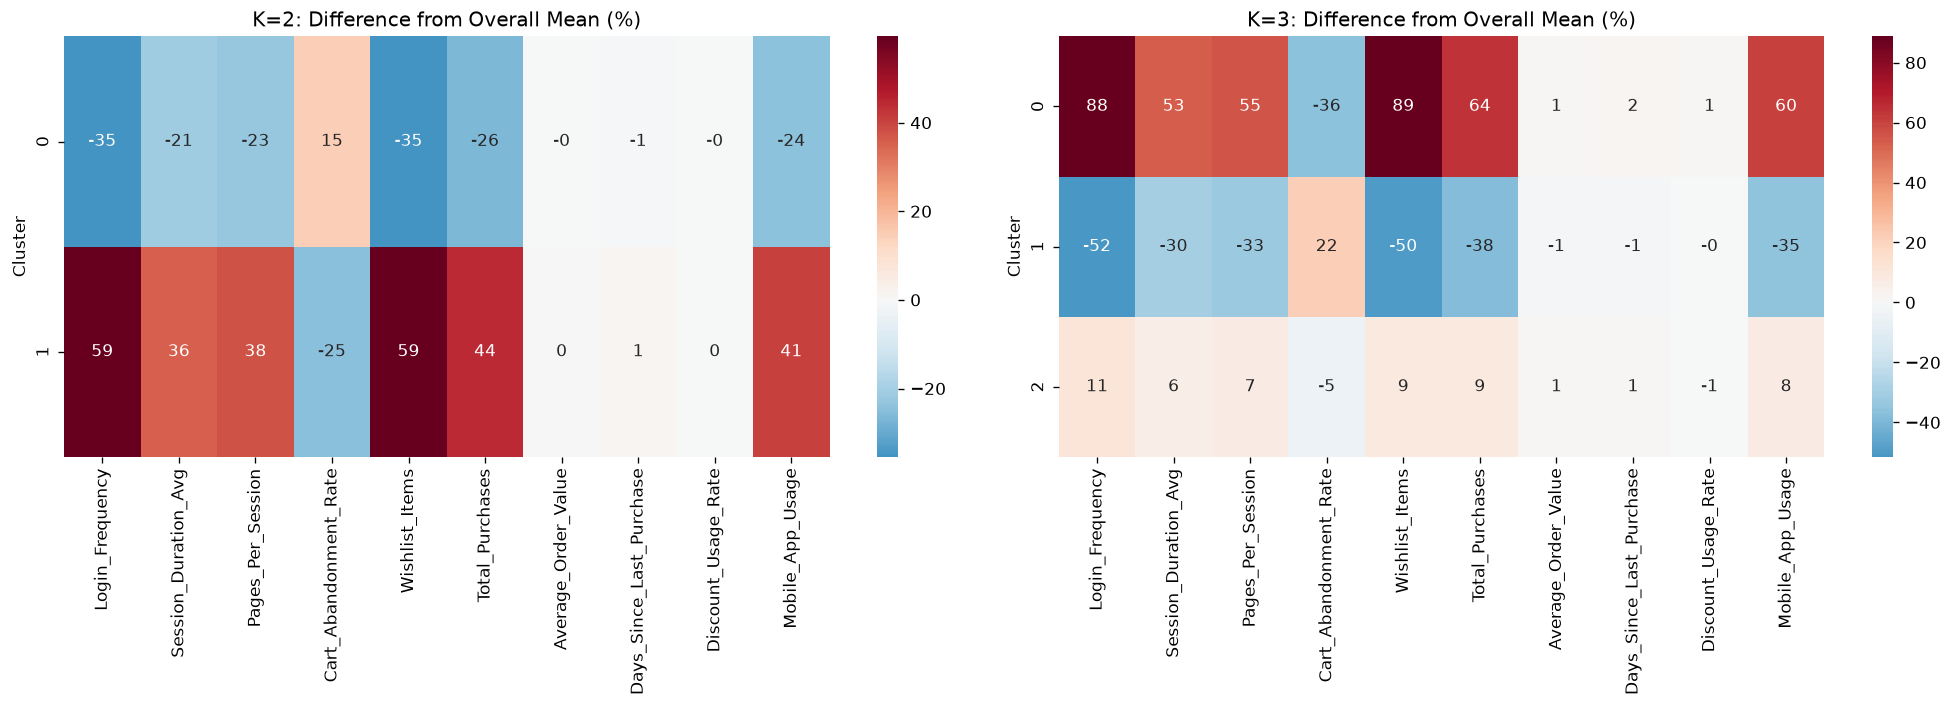

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))

sns.heatmap(
    comparison_k2,
    annot=True,
    fmt=".0f",
    cmap="RdBu_r",
    center=0,
    ax=axes[0],
)
axes[0].set_title("K=2: Difference from Overall Mean (%)")

sns.heatmap(
    comparison_k3,
    annot=True,
    fmt=".0f",
    cmap="RdBu_r",
    center=0,
    ax=axes[1],
)
axes[1].set_title("K=3: Difference from Overall Mean (%)")

plt.tight_layout()
plt.show()

In [29]:
def purchase_level_distribution(df, labels):
    temp = df[["Purchase_Level"]].copy()
    temp["Cluster"] = labels

    return pd.crosstab(
        temp["Cluster"],
        temp["Purchase_Level"],
        normalize="index",
    ) * 100


purchase_k2 = purchase_level_distribution(
    df,
    candidate_labels[2],
)

purchase_k3 = purchase_level_distribution(
    df,
    candidate_labels[3],
)

print("K=2: Purchase Level Distribution (%)")
display(purchase_k2.round(2))

print("K=3: Purchase Level Distribution (%)")
display(purchase_k3.round(2))

K=2: Purchase Level Distribution (%)


Purchase_Level,High,Low,Medium
Cluster,,,
0,8.45,59.73,31.82
1,70.91,1.38,27.71


K=3: Purchase Level Distribution (%)


Purchase_Level,High,Low,Medium
Cluster,,,
0,91.38,0.00,8.62
1,3.21,76.56,20.23
2,32.66,15.99,51.36


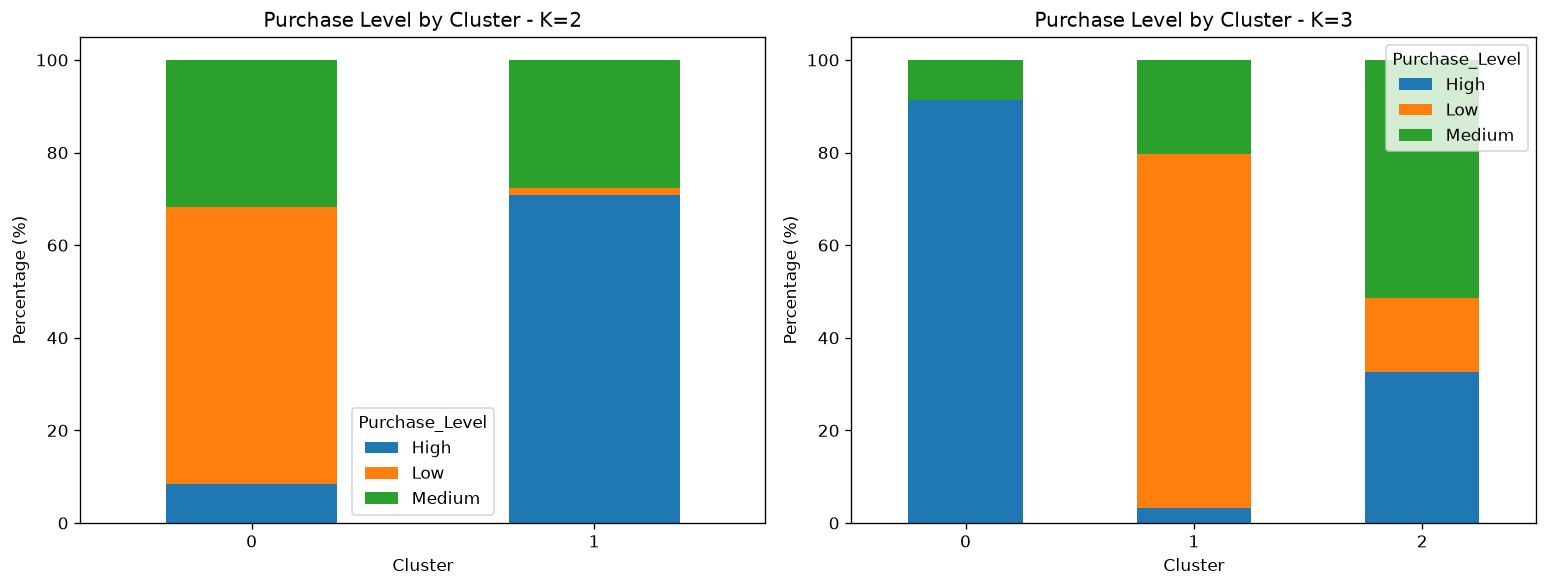

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

purchase_k2.plot(
    kind="bar",
    stacked=True,
    ax=axes[0],
)
axes[0].set_title("Purchase Level by Cluster - K=2")
axes[0].set_ylabel("Percentage (%)")
axes[0].tick_params(axis="x", rotation=0)

purchase_k3.plot(
    kind="bar",
    stacked=True,
    ax=axes[1],
)
axes[1].set_title("Purchase Level by Cluster - K=3")
axes[1].set_ylabel("Percentage (%)")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

In [31]:
FINAL_K = 3
FINAL_FEATURES = CLUSTER_FEATURES.copy()

CLUSTER_NAMES = {
    0: "Khách hàng tích cực",
    1: "Khách hàng ít tương tác",
    2: "Khách hàng tiềm năng",
}

final_kmeans = candidate_models[FINAL_K]
final_labels = candidate_labels[FINAL_K]

print("Final K:", FINAL_K)
print("Features:", len(FINAL_FEATURES))
print("Customers:", len(final_labels))
print("Cluster sizes:", np.bincount(final_labels))

Final K: 3
Features: 10
Customers: 49960
Cluster sizes: [ 9603 20640 19717]


In [32]:
df_segmented = df.copy()

df_segmented["Cluster"] = final_labels
df_segmented["Segment_Name"] = (
    df_segmented["Cluster"].map(CLUSTER_NAMES)
)

display(
    df_segmented[
        [
            "Cluster",
            "Segment_Name",
            "Total_Purchases",
            "Login_Frequency",
            "Cart_Abandonment_Rate",
        ]
    ].head(10)
)

print("\nSegment distribution:")
display(
    df_segmented["Segment_Name"]
    .value_counts()
)

,Cluster,Segment_Name,Total_Purchases,Login_Frequency,Cart_Abandonment_Rate
0,2,Khách hàng tiềm năng,9.0,14.0,50.6
1,2,Khách hàng tiềm năng,19.5,15.0,37.7
2,1,Khách hàng ít tương tác,9.1,10.0,70.9
3,0,Khách hàng tích cực,15.0,10.0,41.7
4,0,Khách hàng tích cực,32.5,29.0,19.1
5,1,Khách hàng ít tương tác,12.0,6.0,74.4
6,0,Khách hàng tích cực,20.0,24.0,36.2
7,1,Khách hàng ít tương tác,13.0,14.0,59.9
8,2,Khách hàng tiềm năng,6.0,14.0,66.5
9,2,Khách hàng tiềm năng,9.0,13.0,62.6



Segment distribution:


,count
Segment_Name,
Khách hàng ít tương tác,20640
Khách hàng tiềm năng,19717
Khách hàng tích cực,9603


In [33]:
pca = PCA(
    n_components=2,
    random_state=RANDOM_STATE,
)

X_pca = pca.fit_transform(X_scaled_clipped)

print(
    "Explained variance ratio:",
    pca.explained_variance_ratio_,
)
print(
    "Total explained variance:",
    round(pca.explained_variance_ratio_.sum(), 4),
)

Explained variance ratio: [0.48817333 0.1003563 ]
Total explained variance: 0.5885


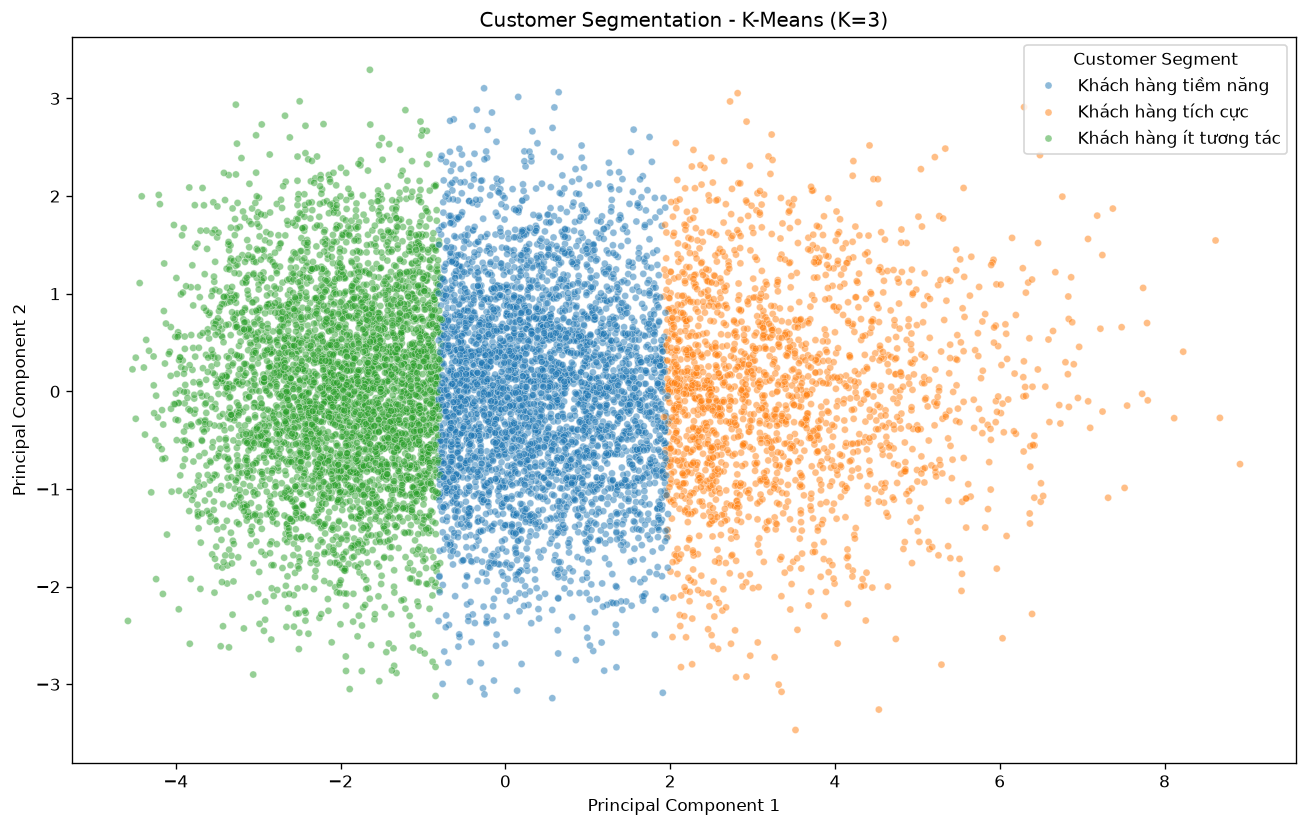

In [34]:
plot_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Segment": df_segmented["Segment_Name"],
})

plot_sample = plot_df.sample(
    n=min(10000, len(plot_df)),
    random_state=RANDOM_STATE,
)

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=plot_sample,
    x="PC1",
    y="PC2",
    hue="Segment",
    alpha=0.5,
    s=18,
)

plt.title("Customer Segmentation - K-Means (K=3)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Customer Segment")
plt.tight_layout()
plt.show()

In [35]:
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
)


final_silhouette = silhouette_score(
    X_scaled_clipped,
    final_labels,
    sample_size=3000,
    random_state=RANDOM_STATE,
)

final_db = davies_bouldin_score(
    X_scaled_clipped,
    final_labels,
)

final_ch = calinski_harabasz_score(
    X_scaled_clipped,
    final_labels,
)

final_metrics = {
    "K": FINAL_K,
    "Silhouette": final_silhouette,
    "Davies_Bouldin": final_db,
    "Calinski_Harabasz": final_ch,
    "Inertia": final_kmeans.inertia_,
}

display(
    pd.DataFrame([final_metrics]).round(4)
)

,K,Silhouette,Davies_Bouldin,Calinski_Harabasz,Inertia
0,3,0.1689,1.7663,17239.6874,295590.5932


In [36]:
final_profile = (
    df_segmented
    .groupby(["Cluster", "Segment_Name"])
    [FINAL_FEATURES]
    .mean()
)

final_sizes = (
    df_segmented
    .groupby(["Cluster", "Segment_Name"])
    .size()
    .rename("Customers")
)

final_summary = final_profile.join(final_sizes)

final_summary["Percentage"] = (
    final_summary["Customers"]
    / len(df_segmented)
    * 100
)

display(final_summary.round(2))

,,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,Total_Purchases,Average_Order_Value,Days_Since_Last_Purchase,Discount_Usage_Rate,Mobile_App_Usage,Customers,Percentage
Cluster,Segment_Name,,,,,,,,,,,,
0,Khách hàng tích cực,21.83,42.27,13.55,36.50,8.07,21.54,124.02,29.75,42.11,30.97,9603,19.22
1,Khách hàng ít tương tác,5.63,19.29,5.85,69.48,2.14,8.10,121.38,28.89,41.58,12.48,20640,41.31
2,Khách hàng tiềm năng,12.93,29.16,9.37,54.04,4.66,14.30,124.47,29.42,41.37,20.75,19717,39.47


In [37]:
from sklearn.base import BaseEstimator, TransformerMixin


class QuantileClipper(BaseEstimator, TransformerMixin):
    def __init__(
        self,
        columns,
        lower_quantile=0.01,
        upper_quantile=0.99,
    ):
        self.columns = columns
        self.lower_quantile = lower_quantile
        self.upper_quantile = upper_quantile

    def fit(self, X, y=None):
        X = pd.DataFrame(X).copy()

        self.feature_names_in_ = list(X.columns)
        self.bounds_ = {}

        for col in self.columns:
            self.bounds_[col] = {
                "lower": float(
                    X[col].quantile(self.lower_quantile)
                ),
                "upper": float(
                    X[col].quantile(self.upper_quantile)
                ),
            }

        return self

    def transform(self, X):
        X = pd.DataFrame(X).copy()
        X = X[self.feature_names_in_]

        for col, bounds in self.bounds_.items():
            X[col] = X[col].clip(
                lower=bounds["lower"],
                upper=bounds["upper"],
            )

        return X

In [38]:
from sklearn.pipeline import Pipeline


clipper = QuantileClipper(
    columns=OUTLIER_FEATURES
)

# Fit để lưu ngưỡng clipping từ dữ liệu huấn luyện hiện tại
clipper.fit(X_cluster)

# Kiểm tra ngưỡng có trùng với checkpoint trước không
for col in OUTLIER_FEATURES:
    assert np.isclose(
        clipper.bounds_[col]["lower"],
        CLIP_BOUNDS[col]["lower"],
    )

    assert np.isclose(
        clipper.bounds_[col]["upper"],
        CLIP_BOUNDS[col]["upper"],
    )

final_pipeline = Pipeline([
    ("clipper", clipper),
    ("scaler", cluster_scaler),
    ("kmeans", final_kmeans),
])

print("Pipeline created successfully.")
print(final_pipeline)

Pipeline created successfully.
Pipeline(steps=[('clipper',
                 QuantileClipper(columns=['Total_Purchases',
                                          'Average_Order_Value'])),
                ('scaler', StandardScaler()),
                ('kmeans', KMeans(n_clusters=3, n_init=10, random_state=42))])


In [39]:
pipeline_labels = final_pipeline.predict(
    X_cluster
)

same_predictions = np.array_equal(
    pipeline_labels,
    final_labels,
)

print("Same predictions:", same_predictions)

assert same_predictions, (
    "Pipeline predictions differ from original K-Means!"
)

print("Pipeline verification passed.")

Same predictions: True
Pipeline verification passed.


In [40]:
import joblib
import json


MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = (
    MODEL_DIR /
    "customer_segmentation_kmeans_pipeline.joblib"
)

METADATA_PATH = (
    MODEL_DIR /
    "customer_segmentation_kmeans_metadata.json"
)

joblib.dump(final_pipeline, MODEL_PATH)

metadata = {
    "model_name": "KMeans Customer Segmentation",
    "algorithm": "KMeans",
    "n_clusters": FINAL_K,
    "features": FINAL_FEATURES,
    "preprocessing": {
        "method": "Quantile Clipping + StandardScaler",
        "clipped_features": OUTLIER_FEATURES,
        "clip_bounds": CLIP_BOUNDS,
    },
    "cluster_names": {
        str(k): v for k, v in CLUSTER_NAMES.items()
    },
    "metrics": {
        "silhouette": float(final_silhouette),
        "davies_bouldin": float(final_db),
        "calinski_harabasz": float(final_ch),
        "inertia": float(final_kmeans.inertia_),
    },
    "random_state": RANDOM_STATE,
}

with open(
    METADATA_PATH,
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        metadata,
        f,
        ensure_ascii=False,
        indent=4,
    )

print("Saved model:", MODEL_PATH)
print("Saved metadata:", METADATA_PATH)
print(
    "Model size (KB):",
    round(MODEL_PATH.stat().st_size / 1024, 2),
)

Saved model: models\customer_segmentation_kmeans_pipeline.joblib
Saved metadata: models\customer_segmentation_kmeans_metadata.json
Model size (KB): 197.67


In [41]:
loaded_pipeline = joblib.load(MODEL_PATH)

loaded_predictions = loaded_pipeline.predict(
    X_cluster.head(100)
)

original_predictions = final_pipeline.predict(
    X_cluster.head(100)
)

assert np.array_equal(
    loaded_predictions,
    original_predictions,
)

print("Reload verification: PASSED")

Reload verification: PASSED


In [42]:
sample_customer = X_cluster.iloc[[0]].copy()

predicted_cluster = int(
    loaded_pipeline.predict(sample_customer)[0]
)

predicted_segment = CLUSTER_NAMES[predicted_cluster]

print("Customer features:")
display(sample_customer)

print("\nPredicted cluster:", predicted_cluster)
print("Segment:", predicted_segment)

Customer features:


,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,Total_Purchases,Average_Order_Value,Days_Since_Last_Purchase,Discount_Usage_Rate,Mobile_App_Usage
0,14.0,27.4,6.0,50.6,3.0,9.0,94.72,34.0,46.4,20.8



Predicted cluster: 2
Segment: Khách hàng tiềm năng


## Portable K-Means Pipeline

"
        "`QuantileClipper` đã được chuyển sang module "
        "`src/features/quantile_clipper.py` để pipeline có thể được tải "
        "trong một tiến trình Python độc lập trước khi tích hợp FastAPI.

In [43]:
import sys

PROJECT_ROOT = Path("..").resolve()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.features.quantile_clipper import (
    QuantileClipper as ModuleClipper,
)

print("Module imported successfully.")
print(ModuleClipper.__module__)

Module imported successfully.
src.features.quantile_clipper


In [44]:
portable_clipper = ModuleClipper(
    columns=OUTLIER_FEATURES
)

portable_clipper.fit(X_cluster)

for col in OUTLIER_FEATURES:
    assert portable_clipper.bounds_[col] == CLIP_BOUNDS[col]

portable_pipeline = Pipeline([
    ("clipper", portable_clipper),
    ("scaler", cluster_scaler),
    ("kmeans", final_kmeans),
])

portable_predictions = portable_pipeline.predict(
    X_cluster
)

assert np.array_equal(
    portable_predictions,
    final_labels,
)

print("Portable pipeline verification: PASSED")

Portable pipeline verification: PASSED


In [45]:
TEMP_MODEL_PATH = (
    MODEL_DIR
    / "customer_segmentation_kmeans_pipeline_test.joblib"
)

joblib.dump(
    portable_pipeline,
    TEMP_MODEL_PATH,
)

print("Temporary model:", TEMP_MODEL_PATH)
print(
    "Size (KB):",
    round(TEMP_MODEL_PATH.stat().st_size / 1024, 2),
)

Temporary model: models\customer_segmentation_kmeans_pipeline_test.joblib
Size (KB): 197.68


In [46]:
import shutil


shutil.copy2(
    TEMP_MODEL_PATH,
    MODEL_PATH,
)

print("Production model updated:", MODEL_PATH)

Production model updated: models\customer_segmentation_kmeans_pipeline.joblib
